# Solving the n-Queens Problem using Local Search

## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
import sys, platform, time, math
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import colors
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | Matplotlib {matplotlib.__version__}")
print(f"Environment: {platform.system()} {platform.release()} | Team: Hải, Ly, Thiện")

Python 3.13.2 | NumPy 2.2.5 | SciPy 1.15.2 | Matplotlib 3.10.0
Environment: Windows 11 | Team: Hải, Ly, Thiện


## The n-Queens Problem 

* __Mục tiêu (Goal):__ Tìm cách xếp $n$ quân hậu trên bàn cờ kích thước $n \times n$ sao cho không có hai quân hậu nào tấn công lẫn nhau (tức không có hai quân nào cùng nằm trên một hàng, một cột, hoặc một đường chéo).

* __Không gian trạng thái (State space):__
  - Một trạng thái được biểu diễn bằng một vector số nguyên $\mathbf{q} = [q_0, q_1, \dots, q_{n-1}]$, trong đó mỗi phần tử $q_i = \text{board}[i]$ là chỉ số hàng ($0 \le q_i < n$) của quân hậu tại cột $i$.
  - **Đặc điểm quan trọng:** Mỗi cột luôn có đúng một quân hậu. Biểu diễn này tự động triệt tiêu hoàn toàn khả năng xung đột cùng cột, giúp thu hẹp không gian tìm kiếm từ $\binom{n^2}{n}$ trạng thái xuống còn $n^n$ trạng thái.
  - Ta gọi trạng thái này là một "bàn cờ" (`board`).

* __Hàm mục tiêu / Hàm xung đột (Objective function $h(\mathbf{q})$):__
  - $h(\mathbf{q}) = \mathrm{conflicts}(\mathbf{q})$ là tổng số cặp quân hậu tấn công lẫn nhau.
  - Xét hai quân hậu bất kỳ tại cột $i$ và cột $j$ ($i < j$), chúng tấn công nhau khi và chỉ khi:
    1. **Cùng hàng (Horizontal conflict):** $\text{board}[i] == \text{board}[j]$
    2. **Cùng đường chéo chính (Main diagonal conflict):** $i - \text{board}[i] == j - \text{board}[j] \iff |i - j| == |\text{board}[i] - \text{board}[j]|$
    3. **Cùng đường chéo phụ (Anti-diagonal conflict):** $i + \text{board}[i] == j + \text{board}[j]$
  - Hàm mục tiêu là bài toán tối thiểu hóa số xung đột:
    $$\min_{\mathbf{q}} h(\mathbf{q}) = \mathrm{conflicts}(\mathbf{q})$$
  - **Ý nghĩa của $h(\mathbf{q}) = 0$:** Vì không có hai quân hậu nào cùng cột trong biểu diễn này, nên $h(\mathbf{q}) = 0$ khi và chỉ khi không còn bất kỳ cặp quân hậu nào xung đột về hàng hoặc đường chéo. Khi đó, $\mathbf{q}$ chính là một **nghiệm hợp lệ (solution)** hoàn hảo của bài toán n-Queens.

* __Nước đi cải thiện cục bộ (Local improvement move):__
  - Chuyển một quân hậu tại cột $i$ bất kỳ sang một hàng khác $r \ne \text{board}[i]$ trong cùng cột đó.
  - Với mỗi trạng thái kích thước $n$, có $n$ cột, mỗi cột có thể di chuyển tới $n - 1$ hàng khác. Do đó, kích thước không gian lân cận (neighborhood size) luôn là:
    $$N = n \times (n - 1)$$
  - Ví dụ: Với $n = 4$, $N = 4 \times 3 = 12$ láng giềng; với $n = 8$, $N = 8 \times 7 = 56$ láng giềng.

* __Điều kiện dừng (Termination):__
  - Đạt nghiệm tối ưu toàn cục ($h = 0$).
  - Hoặc rơi vào cực tiểu cục bộ (local minimum) / bình nguyên (plateau) nơi không còn nước đi cục bộ nào làm giảm xung đột.

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

# Cố định seed mặc định để tái lập kết quả
np.random.seed(1234)

def random_board(n):
    """Tạo một bàn cờ ngẫu nhiên kích thước n x n. Mỗi cột chứa đúng một quân hậu."""
    return np.random.randint(0, n, size=n)

def comb2(n): 
    """Tính tổ hợp chập 2 của n: C(n, 2) = n*(n-1)//2."""
    return n * (n - 1) // 2

def conflicts(board):
    """
    Tính tổng số cặp quân hậu tấn công lẫn nhau trên bàn cờ.
    Độ phức tạp O(n) sử dụng mảng đếm tần suất cho hàng và 2 hướng đường chéo.
    """
    n = len(board)
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * (2 * n)  # Đường chéo phụ: i + board[i]
    diagonal2_cnt = [0] * (2 * n)  # Đường chéo chính: i - board[i] + n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

def show_board(board, cols=['white', 'gray'], fontsize=36, title=None):  
    """Hiển thị bàn cờ và vị trí các quân hậu."""
    n = len(board)
    
    # Tạo nền ô cờ xen kẽ màu
    display = np.zeros([n, n])
    for i in range(n):
        for j in range(n):
            if (i + j) % 2 != 0: 
                display[i, j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots(figsize=(max(4, n * 0.6), max(4, n * 0.6)))
    ax.imshow(display, cmap=cmap, norm=colors.BoundaryNorm(range(len(cols) + 1), cmap.N))
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels([f"C{j}" for j in range(n)])
    ax.set_yticklabels([f"R{i}" for i in range(n)])
    
    # Đặt quân hậu: Unicode \u265B là quân hậu đen
    actual_fontsize = max(14, int(fontsize * 8 / n))
    for j in range(n):
        ax.text(j, board[j], u"\u265B", fontsize=actual_fontsize, 
                horizontalalignment='center', verticalalignment='center',
                color='black')
    
    num_conflicts = conflicts(board)
    if title is None:
        ax.set_title(f"Bàn cờ {n}x{n} | Xung đột: {num_conflicts}", fontsize=12)
    else:
        ax.set_title(f"{title} | Xung đột: {num_conflicts}", fontsize=12)
    plt.tight_layout()
    plt.show()

## Bài 5: Kiểm tra mô hình và các ca thử nghiệm n-Queens

Dưới đây là các ca kiểm thử cho bàn cờ $n = 4$ và $n = 8$, minh họa trực quan bàn cờ và xác thực hàm đếm xung đột $h(\text{board})$:
1. Bàn cờ ngẫu nhiên $n = 4$ có xung đột.
2. Bàn cờ mẫu $n = 4$ không có xung đột (`[1, 3, 0, 2]`) - nghiệm hợp lệ ($h = 0$).
3. Bàn cờ $n = 8$ có xung đột.
4. Bàn cờ nghiệm hợp lệ $n = 8$ (`[0, 4, 7, 5, 2, 6, 1, 3]`) - nghiệm hợp lệ ($h = 0$).

Bàn cờ ngẫu nhiên 4-Queens: [3 3 2 1] | Xung đột: 4


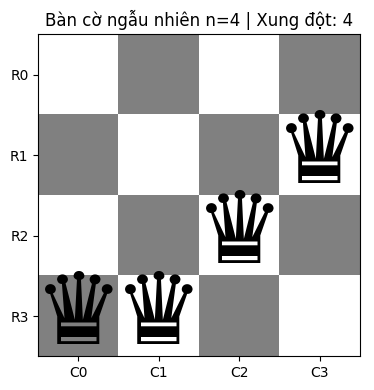

Bàn cờ mẫu 4-Queens: [1, 3, 0, 2] | Xung đột: 0


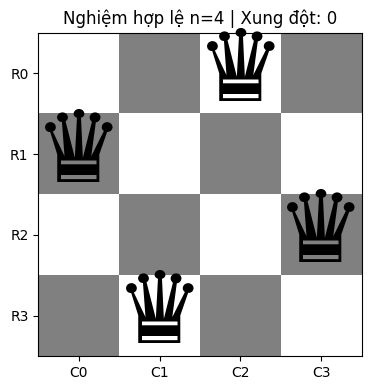

In [3]:
# Kiểm thử và trực quan hóa bàn cờ n = 4
np.random.seed(1234)
board_4_random = random_board(4)
print(f"Bàn cờ ngẫu nhiên 4-Queens: {board_4_random} | Xung đột: {conflicts(board_4_random)}")
show_board(board_4_random, title="Bàn cờ ngẫu nhiên n=4")

board_4_solution = [1, 3, 0, 2]
print(f"Bàn cờ mẫu 4-Queens: {board_4_solution} | Xung đột: {conflicts(board_4_solution)}")
show_board(board_4_solution, title="Nghiệm hợp lệ n=4")

### Bảng kiểm tra xác thực hàm xung đột $h(\text{board})$ trên các cấu hình mẫu

| STT | Bàn cờ | $n$ | Xung đột lý thuyết ($h$ mong đợi) | Kết quả $h$ thực tế | Kết luận trạng thái |
|:---:|:---|:---:|:---:|:---:|:---|
| 1 | `[1, 3, 0, 2]` | 4 | 0 | 0 | Nghiệm hợp lệ ($h = 0$) |
| 2 | `[0, 1, 2, 3]` | 4 | 6 (3 cặp cùng chéo chính + 3 cùng chéo phụ) | 6 | Xung đột đường chéo tối đa |
| 3 | `[2, 2, 2, 2]` | 4 | 6 ($C(4, 2)$ cặp cùng hàng) | 6 | Xung đột hàng tối đa |
| 4 | `[0, 4, 7, 5, 2, 6, 1, 3]` | 8 | 0 | 0 | Nghiệm hợp lệ ($h = 0$) |
| 5 | `[0, 1, 2, 3, 4, 5, 6, 7]` | 8 | 28 ($C(8, 2)$ cặp cùng chéo) | 28 | Cực đại xung đột đường chéo |

Bàn cờ nghiệm n=8: [0, 4, 7, 5, 2, 6, 1, 3] -> Xung đột: 0
Bàn cờ cùng chéo n=8: [0, 1, 2, 3, 4, 5, 6, 7] -> Xung đột: 28


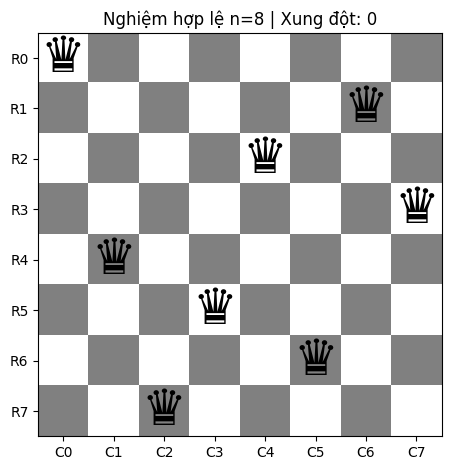

In [4]:
# Kiểm thử và trực quan hóa bàn cờ n = 8
board_8_solution = [0, 4, 7, 5, 2, 6, 1, 3]
board_8_diagonal = [0, 1, 2, 3, 4, 5, 6, 7]

print(f"Bàn cờ nghiệm n=8: {board_8_solution} -> Xung đột: {conflicts(board_8_solution)}")
print(f"Bàn cờ cùng chéo n=8: {board_8_diagonal} -> Xung đột: {conflicts(board_8_diagonal)}")
show_board(board_8_solution, title="Nghiệm hợp lệ n=8")

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascent Hill Climbing Search [20 Points]

### 1. Mô tả thuật toán
- **Ý tưởng:** Tại mỗi bước lặp, thuật toán duyệt qua **toàn bộ** $N = n(n - 1)$ láng giềng trong không gian lân cận (thu được bằng cách thử dời từng quân hậu sang từng hàng khác trong cột của nó).
- **Quy tắc chọn nước đi:** Chọn nước đi mang lại độ giảm xung đột lớn nhất (tức láng giềng có $h(\text{neighbor})$ nhỏ nhất).
  - Nếu có nhiều láng giềng cùng đạt giá trị xung đột nhỏ nhất, thuật toán sẽ chọn ngẫu nhiên đồng đều giữa các ứng viên này để phá hòa (random tie-breaking).
- **Điều kiện dừng:**
  - Nếu $\min h(\text{neighbor}) < h(\text{current})$: Thực hiện nước đi và tiếp tục.
  - Nếu $\min h(\text{neighbor}) \ge h(\text{current})$: Không còn láng giềng nào cải thiện -> Thuật toán đã chạm **cực tiểu cục bộ (local minimum)** hoặc **bình nguyên (plateau)**, dừng tìm kiếm.
  - Nếu $h(\text{current}) = 0$: Tìm thấy nghiệm tối ưu toàn cục.
  - Vượt quá `max_steps`: Ngăn ngừa lặp vô hạn.

### 2. Quy ước chuẩn giao tiếp kết quả
Hàm trả về một `dict` đồng nhất phục vụ tích hợp và benchmark:
`{'algorithm', 'problem', 'n', 'seed', 'success', 'runtime_s', 'steps', 'evaluations', 'final_conflicts', 'board', 'history'}`.
Mỗi lần gọi `conflicts()` để đánh giá trạng thái khởi tạo hay trạng thái láng giềng đều được cộng chính xác vào `evaluations`.

=== THỬ NGHIỆM STEEPEST-ASCENT HILL CLIMBING ===
n=4 | Thành công: True | Xung đột cuối: 0 | Bước: 1 | Đánh giá: 13 | Thời gian: 0.000083s
Lịch sử xung đột: [3, 0]


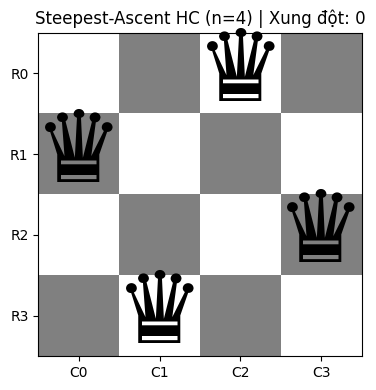

n=8 | Thành công: False | Xung đột cuối: 2 | Bước: 3 | Đánh giá: 225 | Thời gian: 0.001492s
Lịch sử xung đột: [11, 5, 3, 2]


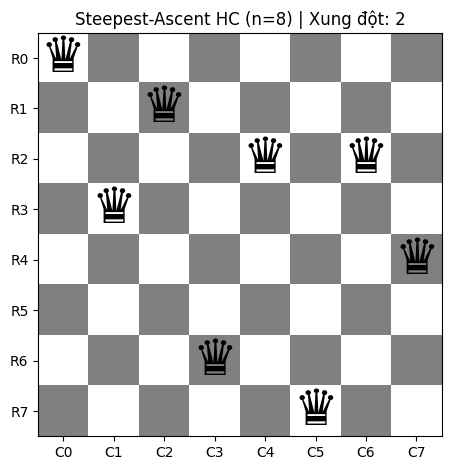

In [5]:
def steepest_ascent_hill_climbing(n=None, initial_board=None, max_steps=1000, seed=None):
    """
    Thuật toán Leo đồi dốc nhất (Steepest-Ascent Hill Climbing) cho n-Queens.
    Duyệt toàn bộ n*(n-1) láng giềng ở mỗi bước, chọn láng giềng tốt nhất.
    """
    if seed is not None:
        np.random.seed(seed)
        
    if initial_board is None:
        if n is None:
            raise ValueError("Cần cung cấp n hoặc initial_board.")
        board = random_board(n)
    else:
        board = np.array(initial_board, copy=True)
        n = len(board)
        
    start_time = time.perf_counter()
    curr_h = conflicts(board)
    evaluations = 1
    history = [int(curr_h)]
    steps = 0
    
    while steps < max_steps and curr_h > 0:
        best_h = curr_h
        best_moves = []
        
        # Đánh giá toàn bộ n*(n - 1) láng giềng
        for col in range(n):
            orig_row = board[col]
            for row in range(n):
                if row == orig_row:
                    continue
                board[col] = row
                h = conflicts(board)
                evaluations += 1
                
                if h < best_h:
                    best_h = h
                    best_moves = [(col, row)]
                elif h == best_h and best_h < curr_h:
                    best_moves.append((col, row))
            board[col] = orig_row  # Hoàn tác
            
        # Kiểm tra cải thiện
        if best_h < curr_h:
            # Chọn ngẫu nhiên giữa các nước đi tốt nhất tương đương (tie-breaking)
            chosen_col, chosen_row = best_moves[np.random.randint(len(best_moves))]
            board[chosen_col] = chosen_row
            curr_h = best_h
            steps += 1
            history.append(int(curr_h))
        else:
            # Chạm cực tiểu cục bộ hoặc bình nguyên
            break
            
    runtime_s = time.perf_counter() - start_time
    
    return {
        "algorithm": "Steepest-Ascent HC",
        "problem": "n_queens",
        "n": n,
        "seed": seed,
        "success": bool(curr_h == 0),
        "runtime_s": runtime_s,
        "steps": steps,
        "evaluations": evaluations,
        "final_conflicts": int(curr_h),
        "board": board.tolist(),
        "history": history
    }

# Chạy thử nghiệm trên n = 4 và n = 8
print("=== THỬ NGHIỆM STEEPEST-ASCENT HILL CLIMBING ===")
res_steep_4 = steepest_ascent_hill_climbing(n=4, seed=42)
print(f"n=4 | Thành công: {res_steep_4['success']} | Xung đột cuối: {res_steep_4['final_conflicts']} | Bước: {res_steep_4['steps']} | Đánh giá: {res_steep_4['evaluations']} | Thời gian: {res_steep_4['runtime_s']:.6f}s")
print(f"Lịch sử xung đột: {res_steep_4['history']}")
show_board(res_steep_4['board'], title="Steepest-Ascent HC (n=4)")

res_steep_8 = steepest_ascent_hill_climbing(n=8, seed=42)
print(f"n=8 | Thành công: {res_steep_8['success']} | Xung đột cuối: {res_steep_8['final_conflicts']} | Bước: {res_steep_8['steps']} | Đánh giá: {res_steep_8['evaluations']} | Thời gian: {res_steep_8['runtime_s']:.6f}s")
print(f"Lịch sử xung đột: {res_steep_8['history']}")
show_board(res_steep_8['board'], title="Steepest-Ascent HC (n=8)")

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

### 1. Mô tả thuật toán
- **Ý tưởng:** Tương tự như Steepest-Ascent, thuật toán vẫn phải **tính toán hàm mục tiêu cho toàn bộ** $N = n(n - 1)$ láng giềng ở mỗi bước.
- **Điểm khác biệt:** Thay vì chọn nước đi tốt nhất (có $h$ nhỏ nhất), thuật toán lập danh sách **tất cả các nước đi cải thiện** ($h(\text{neighbor}) < h(\text{current})$), sau đó chọn ngẫu nhiên đồng đều một nước đi từ danh sách này.
- **Điều kiện dừng:** Dừng khi không còn nước đi nào cải thiện ($h(\text{neighbor}) \ge h(\text{current})$ với mọi láng giềng), hoặc khi đạt $h = 0$, hoặc vượt quá `max_steps`.
- **Đánh giá:** Thuật toán này rất tốn kém tài nguyên tính toán (inefficient) vì phải tốn $O(n^2)$ phép đánh giá mỗi bước nhưng lại không tận dụng tối đa mức độ cải thiện lớn nhất của láng giềng.

=== THỬ NGHIỆM INEFFICIENT STOCHASTIC HILL CLIMBING ===
n=4 | Thành công: True | Xung đột cuối: 0 | Bước: 2 | Đánh giá: 25 | Thời gian: 0.000131s
Lịch sử xung đột: [3, 1, 0]


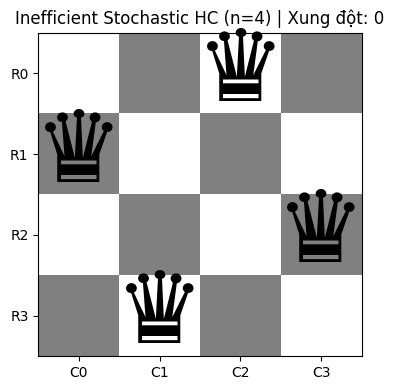

n=8 | Thành công: False | Xung đột cuối: 2 | Bước: 5 | Đánh giá: 337 | Thời gian: 0.002189s
Lịch sử xung đột: [11, 9, 7, 4, 3, 2]


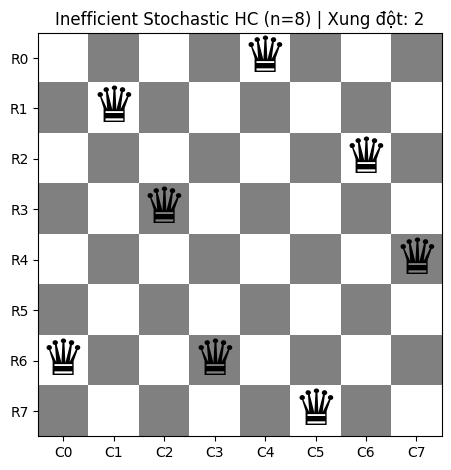

In [6]:
def inefficient_stochastic_hill_climbing(n=None, initial_board=None, max_steps=1000, seed=None):
    """
    Thuật toán Leo đồi ngẫu nhiên không hiệu quả (Inefficient Stochastic Hill Climbing).
    Đánh giá toàn bộ n*(n-1) láng giềng, chọn ngẫu nhiên một trong các nước đi cải thiện.
    """
    if seed is not None:
        np.random.seed(seed)
        
    if initial_board is None:
        if n is None:
            raise ValueError("Cần cung cấp n hoặc initial_board.")
        board = random_board(n)
    else:
        board = np.array(initial_board, copy=True)
        n = len(board)
        
    start_time = time.perf_counter()
    curr_h = conflicts(board)
    evaluations = 1
    history = [int(curr_h)]
    steps = 0
    
    while steps < max_steps and curr_h > 0:
        improving_moves = []
        
        # Đánh giá toàn bộ n*(n - 1) láng giềng
        for col in range(n):
            orig_row = board[col]
            for row in range(n):
                if row == orig_row:
                    continue
                board[col] = row
                h = conflicts(board)
                evaluations += 1
                
                # Gom tất cả các nước đi có cải thiện
                if h < curr_h:
                    improving_moves.append((col, row, h))
            board[col] = orig_row  # Hoàn tác
            
        # Kiểm tra xem có nước đi cải thiện nào không
        if improving_moves:
            # Chọn ngẫu nhiên đều một nước đi cải thiện
            idx = np.random.randint(len(improving_moves))
            chosen_col, chosen_row, next_h = improving_moves[idx]
            board[chosen_col] = chosen_row
            curr_h = next_h
            steps += 1
            history.append(int(curr_h))
        else:
            # Không còn nước đi cải thiện -> local optimum / plateau
            break
            
    runtime_s = time.perf_counter() - start_time
    
    return {
        "algorithm": "Inefficient Stochastic HC",
        "problem": "n_queens",
        "n": n,
        "seed": seed,
        "success": bool(curr_h == 0),
        "runtime_s": runtime_s,
        "steps": steps,
        "evaluations": evaluations,
        "final_conflicts": int(curr_h),
        "board": board.tolist(),
        "history": history
    }

# Chạy thử nghiệm trên n = 4 và n = 8
print("=== THỬ NGHIỆM INEFFICIENT STOCHASTIC HILL CLIMBING ===")
res_ineff_4 = inefficient_stochastic_hill_climbing(n=4, seed=42)
print(f"n=4 | Thành công: {res_ineff_4['success']} | Xung đột cuối: {res_ineff_4['final_conflicts']} | Bước: {res_ineff_4['steps']} | Đánh giá: {res_ineff_4['evaluations']} | Thời gian: {res_ineff_4['runtime_s']:.6f}s")
print(f"Lịch sử xung đột: {res_ineff_4['history']}")
show_board(res_ineff_4['board'], title="Inefficient Stochastic HC (n=4)")

res_ineff_8 = inefficient_stochastic_hill_climbing(n=8, seed=42)
print(f"n=8 | Thành công: {res_ineff_8['success']} | Xung đột cuối: {res_ineff_8['final_conflicts']} | Bước: {res_ineff_8['steps']} | Đánh giá: {res_ineff_8['evaluations']} | Thời gian: {res_ineff_8['runtime_s']:.6f}s")
print(f"Lịch sử xung đột: {res_ineff_8['history']}")
show_board(res_ineff_8['board'], title="Inefficient Stochastic HC (n=8)")

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

### 1. Mô tả thuật toán (First-choice Hill Climbing)
- **Ý tưởng:** Trong thực tế, thay vì duyệt toàn bộ $N = n(n - 1)$ láng giềng, thuật toán chỉ **sinh ngẫu nhiên từng láng giềng một**.
  - Ngay khi gặp một láng giềng có $h(\text{neighbor}) < h(\text{current})$, thuật toán **chấp nhận ngay lập tức** nước đi đó mà không cần đánh giá thêm bất kỳ láng giềng nào khác.
  - Sau khi chấp nhận, bộ đếm số lần thử thất bại liên tiếp được đặt lại về 0.

### 2. Phân tích điều kiện dừng và luận giải tham số $x$ (`max_attempts`)
- Vì thuật toán không duyệt toàn bộ láng giềng cùng lúc, làm sao để biết ta đã chạm cực tiểu cục bộ?
- **Luận giải toán học:**
  - Không gian lân cận có tổng cộng $N = n(n - 1)$ láng giềng.
  - Việc sinh láng giềng ngẫu nhiên là quá trình lấy mẫu độc lập có hoàn lại với xác suất chọn mỗi láng giềng là $1/N$.
  - Giả sử trong không gian chỉ còn duy nhất 1 nước đi cải thiện. Xác suất để một lần thử ngẫu nhiên **không** chọn trúng nước đi này là $1 - 1/N$.
  - Sau $x$ lần thử độc lập liên tiếp, xác suất bỏ lọt nước đi cải thiện đó là:
    $$P(\text{bỏ lọt}) = \left(1 - \frac{1}{N}\right)^x \approx e^{-x/N}$$
  - Để đảm bảo độ tin cậy $\ge 95\%$ (tức xác suất bỏ lọt $\le 5\%$):
    $$e^{-x/N} \le 0.05 \iff -\frac{x}{N} \le \ln(0.05) \approx -2.996 \iff x \ge 3N = 3n(n - 1)$$
  - Để đảm bảo độ tin cậy $\ge 99\%$ (xác suất bỏ lọt $\le 1\%$): $x \ge \ln(100) \times N \approx 4.6 N$.
  - Do đó, ta thiết lập giá trị ngưỡng dừng hợp lý là:
    $$\text{max\_attempts} = \max(100, 3 \times n(n - 1))$$
  - Ví dụ: Với $n = 4$, $N = 12 \implies \text{max\_attempts} = 100$; với $n = 8$, $N = 56 \implies \text{max\_attempts} = 168$. Thiết lập này vừa ngăn chặn vòng lặp vô hạn trên plateau, vừa đảm bảo xấp xỉ toàn bộ lân cận đã được kiểm tra.

=== THỬ NGHIỆM EFFICIENT STOCHASTIC HILL CLIMBING ===
n=4 | Thành công: True | Xung đột cuối: 0 | Bước: 2 | Đánh giá: 12 | Thời gian: 0.000110s
Lịch sử xung đột: [3, 1, 0]


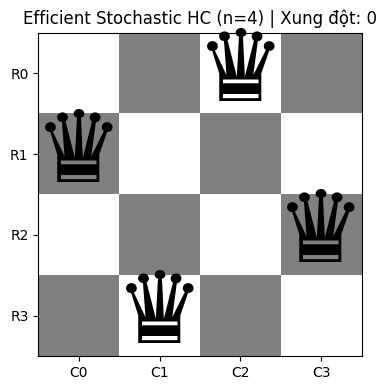

n=8 | Thành công: False | Xung đột cuối: 1 | Bước: 5 | Đánh giá: 179 | Thời gian: 0.001825s
Lịch sử xung đột: [11, 8, 5, 4, 2, 1]


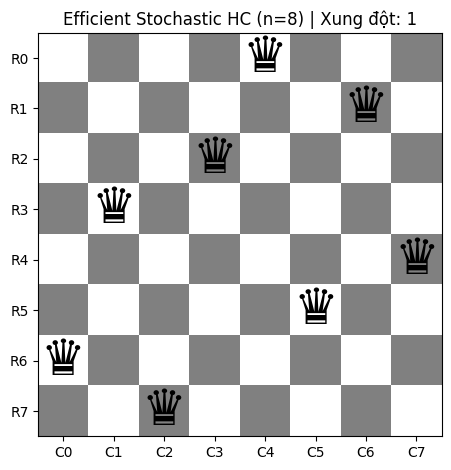

In [7]:
def efficient_stochastic_hill_climbing(n=None, initial_board=None, max_attempts=None, max_steps=1000, seed=None):
    """
    Thuật toán Leo đồi ngẫu nhiên hiệu quả / First-choice Hill Climbing.
    Sinh ngẫu nhiên từng láng giềng, chấp nhận ngay khi có cải thiện.
    Dừng khi không tìm được nước đi cải thiện sau max_attempts lần thử liên tiếp.
    """
    if seed is not None:
        np.random.seed(seed)
        
    if initial_board is None:
        if n is None:
            raise ValueError("Cần cung cấp n hoặc initial_board.")
        board = random_board(n)
    else:
        board = np.array(initial_board, copy=True)
        n = len(board)
        
    # Luận giải số lần thử tối đa dựa trên kích thước không gian lân cận N = n*(n-1)
    if max_attempts is None:
        max_attempts = max(100, 3 * n * (n - 1))
        
    start_time = time.perf_counter()
    curr_h = conflicts(board)
    evaluations = 1
    history = [int(curr_h)]
    steps = 0
    consecutive_fails = 0
    
    while steps < max_steps and curr_h > 0 and consecutive_fails < max_attempts:
        # Sinh ngẫu nhiên một láng giềng (chọn cột ngẫu nhiên và hàng khác hàng hiện tại)
        col = np.random.randint(0, n)
        current_row = board[col]
        new_row = np.random.randint(0, n - 1)
        if new_row >= current_row:
            new_row += 1
            
        board[col] = new_row
        h = conflicts(board)
        evaluations += 1
        
        if h < curr_h:
            # Chấp nhận ngay lập tức (First-choice)
            curr_h = h
            steps += 1
            history.append(int(curr_h))
            consecutive_fails = 0
        else:
            # Hoàn tác và ghi nhận 1 lần thử không thành công
            board[col] = current_row
            consecutive_fails += 1
            
    runtime_s = time.perf_counter() - start_time
    
    return {
        "algorithm": "Efficient Stochastic HC",
        "problem": "n_queens",
        "n": n,
        "seed": seed,
        "success": bool(curr_h == 0),
        "runtime_s": runtime_s,
        "steps": steps,
        "evaluations": evaluations,
        "final_conflicts": int(curr_h),
        "board": board.tolist(),
        "history": history
    }

# Chạy thử nghiệm trên n = 4 và n = 8
print("=== THỬ NGHIỆM EFFICIENT STOCHASTIC HILL CLIMBING ===")
res_eff_4 = efficient_stochastic_hill_climbing(n=4, seed=42)
print(f"n=4 | Thành công: {res_eff_4['success']} | Xung đột cuối: {res_eff_4['final_conflicts']} | Bước: {res_eff_4['steps']} | Đánh giá: {res_eff_4['evaluations']} | Thời gian: {res_eff_4['runtime_s']:.6f}s")
print(f"Lịch sử xung đột: {res_eff_4['history']}")
show_board(res_eff_4['board'], title="Efficient Stochastic HC (n=4)")

res_eff_8 = efficient_stochastic_hill_climbing(n=8, seed=42)
print(f"n=8 | Thành công: {res_eff_8['success']} | Xung đột cuối: {res_eff_8['final_conflicts']} | Bước: {res_eff_8['steps']} | Đánh giá: {res_eff_8['evaluations']} | Thời gian: {res_eff_8['runtime_s']:.6f}s")
print(f"Lịch sử xung đột: {res_eff_8['history']}")
show_board(res_eff_8['board'], title="Efficient Stochastic HC (n=8)")

### Nhận xét về Local Optimum, Plateau và chi phí đánh giá

Hill Climbing có thể bị mắc kẹt tại local optimum khi không có láng giềng nào giúp giảm số xung đột. Plateau là vùng mà các trạng thái lân cận không tạo ra sự cải thiện rõ rệt, khiến quá trình tìm kiếm khó tiếp tục. 

Steepest-ascent và Inefficient Stochastic đều đánh giá toàn bộ \(n(n-1)\) láng giềng ở mỗi bước, nhưng lần lượt chọn nước đi tốt nhất và chọn ngẫu nhiên một nước đi cải thiện. 

Vì vậy, hai thuật toán này có chi phí đánh giá lớn hơn Efficient Stochastic, vốn chỉ sinh và đánh giá từng láng giềng cho đến khi tìm được nước đi cải thiện. Tuy nhiên, Efficient Stochastic có thể cần nhiều lần thử thất bại và không đảm bảo tìm được nghiệm. Random Restart giúp tăng cơ hội thoát khỏi trạng thái khởi tạo không thuận lợi, trong khi Simulated Annealing có thể chấp nhận nước đi xấu hơn để vượt qua một số bẫy cực tiểu cục bộ.

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

### 1. Mô tả thuật toán và sự cần thiết
- **Vấn đề của Hill Climbing:** Cả ba biến thể leo đồi đơn lẻ đều là tìm kiếm cục bộ thuần túy (greedy local search), rất dễ bị kẹt vĩnh viễn trong các cực tiểu cục bộ (local minima) hoặc dải bình nguyên (plateau). Thực tế cho thấy với bàn cờ $n = 8$, Steepest HC bị kẹt tới khoảng $86\%$ số lần chạy (chỉ đạt tỷ lệ thành công xấp xỉ $14\%$ từ một trạng thái ngẫu nhiên duy nhất).
- **Giải pháp Random Restart:** Khắc phục nhược điểm này bằng cách khởi động lại thuật toán từ một bàn cờ khởi tạo ngẫu nhiên hoàn toàn mới mỗi khi bị kẹt.
- **Quy tắc thực hiện:**
  - Áp dụng wrapper tổng quát cho bất kỳ biến thể leo đồi nào trong số 3 thuật toán đã cài.
  - Số lần restart tối đa: `max_restarts = 100`.
  - **Dừng sớm (Early stopping):** Ngay khi tìm thấy một nghiệm tối ưu ($h = 0$), thuật toán dừng ngay lập tức mà không cần chạy hết số lần restart.
  - **Quy ước tính chi phí tích lũy:** Tổng số lần đánh giá hàm mục tiêu (`evaluations`), tổng số bước thực hiện (`steps`) và tổng thời gian (`runtime_s`) được cộng dồn chuẩn xác qua tất cả các lượt restart đã chạy.
  - Luôn lưu giữ nghiệm tốt nhất (`best_board`, `best_conflicts`) gặp được trong toàn bộ quá trình.

=== THỬ NGHIỆM RANDOM RESTART HILL CLIMBING ===
[Steepest HC + RR] n=8 | Thành công: True | Xung đột cuối: 0 | Restarts: 4 | Tổng đánh giá: 1012 | Thời gian: 0.0065s
[Inefficient HC + RR] n=8 | Thành công: True | Xung đột cuối: 0 | Restarts: 4 | Tổng đánh giá: 1236 | Thời gian: 0.0070s
[Efficient HC + RR] n=8 | Thành công: True | Xung đột cuối: 0 | Restarts: 13 | Tổng đánh giá: 2760 | Thời gian: 0.0285s


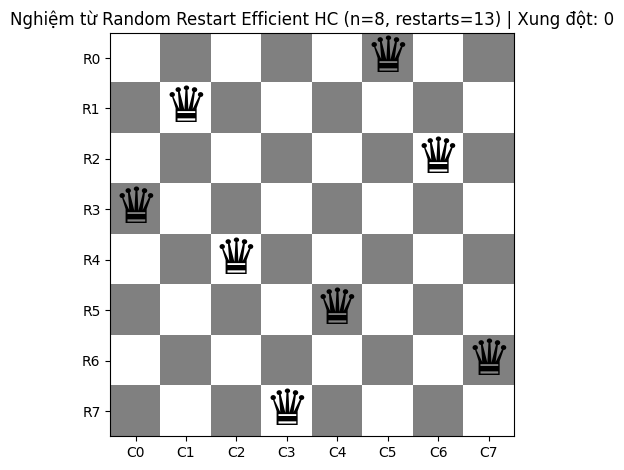

In [8]:
def random_restart_hill_climbing(hc_func, n, max_restarts=100, seed=None, initial_board=None, **kwargs):
    """
    Wrapper Random Restart cho các thuật toán Hill Climbing.
    Khởi động lại tối đa max_restarts lần với bàn cờ ngẫu nhiên mới.
    Dừng sớm khi đạt h = 0 và cộng dồn toàn bộ chi phí tính toán.
    """
    if seed is not None:
        np.random.seed(seed)
        
    start_time = time.perf_counter()
    total_evaluations = 0
    total_steps = 0
    best_conflicts = float('inf')
    best_board = None
    best_history = []
    restarts_done = 0
    
    for k in range(max_restarts):
        restarts_done += 1
        # Khởi tạo bàn cờ ngẫu nhiên mới cho mỗi lượt restart
        init_board = np.array(initial_board, copy=True) if k == 0 and initial_board is not None else random_board(n)
        
        # Chạy thuật toán cơ sở
        res = hc_func(initial_board=init_board, **kwargs)
        
        total_evaluations += res["evaluations"]
        total_steps += res["steps"]
        
        # Cập nhật nghiệm tốt nhất tìm được
        if res["final_conflicts"] < best_conflicts:
            best_conflicts = res["final_conflicts"]
            best_board = res["board"]
            best_history = res["history"]
            
        # Dừng sớm nếu tìm thấy nghiệm tối ưu toàn cục (h = 0)
        if best_conflicts == 0:
            break
            
    total_runtime = time.perf_counter() - start_time
    algo_name = hc_func.__name__.replace("_", " ").title()
    
    return {
        "algorithm": f"Random Restart ({algo_name})",
        "problem": "n_queens",
        "n": n,
        "seed": seed,
        "success": bool(best_conflicts == 0),
        "runtime_s": total_runtime,
        "steps": total_steps,
        "evaluations": total_evaluations,
        "final_conflicts": int(best_conflicts),
        "board": best_board,
        "restarts": restarts_done,
        "history": best_history
    }

# Chạy thử nghiệm Random Restart kết hợp với cả 3 biến thể trên n = 4 và n = 8
print("=== THỬ NGHIỆM RANDOM RESTART HILL CLIMBING ===")
algorithms = [
    ("Steepest HC", steepest_ascent_hill_climbing),
    ("Inefficient HC", inefficient_stochastic_hill_climbing),
    ("Efficient HC", efficient_stochastic_hill_climbing)
]

for name, func in algorithms:
    res = random_restart_hill_climbing(func, n=8, max_restarts=100, seed=123)
    print(f"[{name} + RR] n=8 | Thành công: {res['success']} | Xung đột cuối: {res['final_conflicts']} | Restarts: {res['restarts']} | Tổng đánh giá: {res['evaluations']} | Thời gian: {res['runtime_s']:.4f}s")

# Hiển thị bàn cờ nghiệm thu được từ Random Restart + Efficient HC
res_demo = random_restart_hill_climbing(efficient_stochastic_hill_climbing, n=8, max_restarts=100, seed=123)
show_board(res_demo['board'], title=f"Nghiệm từ Random Restart Efficient HC (n=8, restarts={res_demo['restarts']})")

## Task 5: Simulated Annealing [10 Points]

### 1. Mô tả thuật toán Simulated Annealing
- **Cơ chế hoạt động:**
  - Lấy cảm hứng từ quá trình nhiệt luyện kim loại trong vật lý: nung nóng kim loại lên nhiệt độ cao rồi làm nguội từ từ để các nguyên tử sắp xếp về trạng thái có mức năng lượng cực tiểu.
  - Tại mỗi bước, thuật toán chọn ngẫu nhiên một láng giềng và tính độ chênh lệch xung đột $\Delta h = h(\text{neighbor}) - h(\text{current})$.
  - Nếu $\Delta h < 0$ (nước đi tốt hơn): **Luôn luôn chấp nhận**.
  - Nếu $\Delta h \ge 0$ (nước đi xấu hơn hoặc bằng): Chấp nhận với xác suất $P = \exp(-\Delta h / T)$, trong đó $T > 0$ là nhiệt độ hiện tại.
  - Khi nhiệt độ $T$ cao (giai đoạn đầu), $P \approx 1$, thuật toán dễ dàng chấp nhận các bước nhảy xấu để thoát khỏi các bẫy cực tiểu cục bộ.
  - Khi nhiệt độ $T$ giảm dần (làm nguội), $P \to 0$, thuật toán dần chuyển thành tìm kiếm cục bộ thuần túy để hội tụ về nghiệm tối ưu.

### 2. Hai lịch làm nguội (Cooling Schedules)
Thuật toán hỗ trợ và thử nghiệm ít nhất hai lịch làm nguội khác nhau:
1. **Lịch Geometric (Hàm mũ / Cấp số nhân):**
   $$T_{k+1} = \alpha \times T_k \quad (0 < \alpha < 1, \text{ thường chọn } \alpha = 0.95)$$
   Nhiệt độ giảm đều đặn theo hàm mũ qua mỗi bước lặp.
2. **Lịch Inverse (Nghịch đảo / Tuyến tính chậm):**
   $$T_k = \frac{T_0}{1 + \beta \times k} \quad (\beta > 0, \text{ ví dụ } \beta = 0.005)$$
   Nhiệt độ giảm nhanh lúc đầu nhưng giảm chậm dần về sau, cho phép duy trì sự thăm dò lâu hơn ở vùng nhiệt độ trung bình.

### 3. Giữ lại trạng thái tốt nhất đã gặp (`best-so-far`)
- **Yêu cầu quan trọng:** Do Simulated Annealing cho phép chấp nhận các nước đi xấu hơn, trạng thái tại bước cuối cùng của thuật toán có thể không phải là trạng thái tốt nhất (có thể vừa chấp nhận một bước xấu ngay trước khi hết nhiệt độ).
- Vì vậy, thuật toán luôn duy trì biến `best_board` và `best_conflicts` được cập nhật liên tục để đảm bảo không bao giờ làm mất nghiệm tối ưu đã tìm thấy trong hành trình.

Bàn cờ khởi đầu (n=8): [0, 7, 1, 7, 0, 1, 1, 4] với 6 xung đột.
[SA Geometric] Thành công: True | Xung đột tốt nhất: 0 | Bước: 362 | Thời gian: 0.0033s
[SA Inverse]   Thành công: True | Xung đột tốt nhất: 0 | Bước: 1153 | Thời gian: 0.0114s


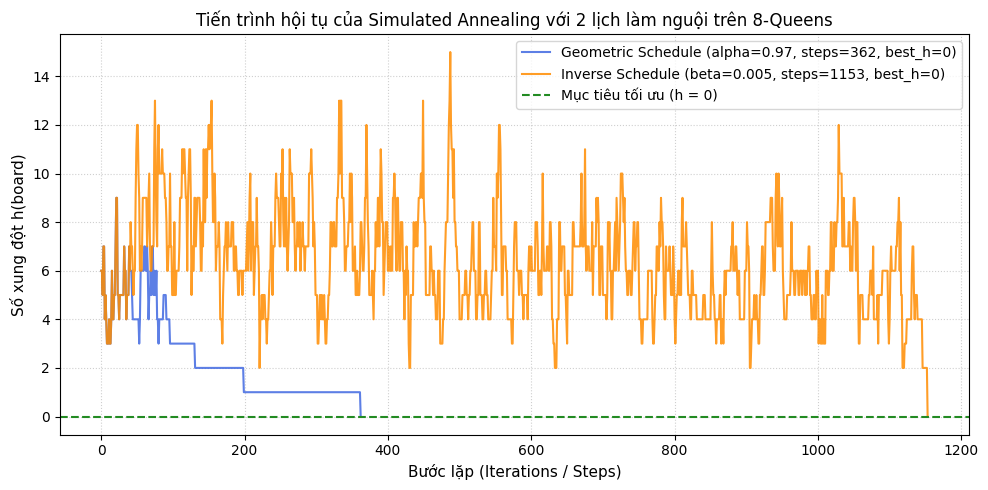

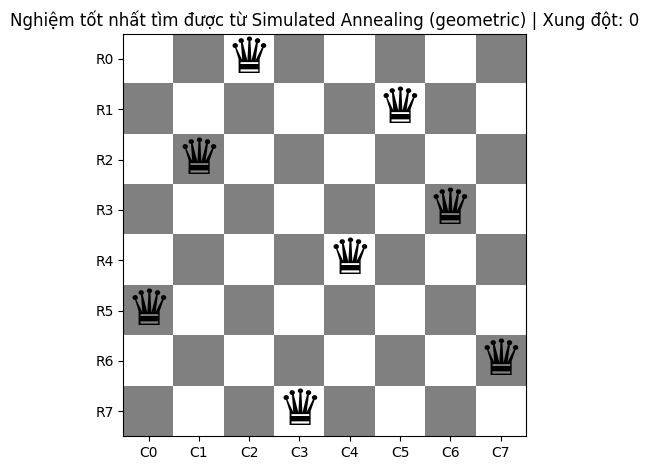

In [9]:
def simulated_annealing(n=None, initial_board=None, schedule='geometric', 
                        T0=10.0, alpha=0.95, beta=0.005, min_T=1e-4, 
                        max_steps=5000, seed=None):
    """
    Thuật toán Simulated Annealing cho n-Queens.
    Hỗ trợ hai lịch làm nguội: 'geometric' và 'inverse'.
    Lưu giữ và trả về cả nghiệm tốt nhất (best-so-far) lẫn trạng thái cuối cùng.
    """
    if seed is not None:
        np.random.seed(seed)
        
    if initial_board is None:
        if n is None:
            raise ValueError("Cần cung cấp n hoặc initial_board.")
        board = random_board(n)
    else:
        board = np.array(initial_board, copy=True)
        n = len(board)
        
    start_time = time.perf_counter()
    curr_h = conflicts(board)
    evaluations = 1
    history = [int(curr_h)]
    
    # Lưu giữ trạng thái tốt nhất đã gặp
    best_board = board.copy()
    best_conflicts = int(curr_h)
    
    steps = 0
    T = float(T0)
    
    while steps < max_steps and best_conflicts > 0 and T > min_T:
        steps += 1
        
        # Sinh ngẫu nhiên một láng giềng
        col = np.random.randint(0, n)
        current_row = board[col]
        new_row = np.random.randint(0, n - 1)
        if new_row >= current_row:
            new_row += 1
            
        board[col] = new_row
        h = conflicts(board)
        evaluations += 1
        delta_h = h - curr_h
        
        # Tiêu chuẩn chấp nhận Metropolis
        accept = False
        if delta_h < 0:
            accept = True
        else:
            prob = math.exp(-delta_h / T)
            if np.random.rand() < prob:
                accept = True
                
        if accept:
            curr_h = h
            if curr_h < best_conflicts:
                best_conflicts = int(curr_h)
                best_board = board.copy()
        else:
            board[col] = current_row  # Hoàn tác nếu không chấp nhận
            
        history.append(int(curr_h))
        
        # Cập nhật nhiệt độ theo lịch làm nguội
        if schedule == 'geometric':
            T = T * alpha
        elif schedule == 'inverse':
            T = T0 / (1.0 + beta * steps)
        elif schedule == 'logarithmic':
            T = T0 / math.log(1.0 + steps + 1.0)
        else:
            raise ValueError(f"Lịch làm nguội không hợp lệ: {schedule}")
            
    runtime_s = time.perf_counter() - start_time
    
    return {
        "algorithm": f"Simulated Annealing ({schedule})",
        "problem": "n_queens",
        "n": n,
        "seed": seed,
        "schedule": schedule,
        "success": bool(best_conflicts == 0),
        "runtime_s": runtime_s,
        "steps": steps,
        "evaluations": evaluations,
        "final_conflicts": int(best_conflicts),
        "board": best_board.tolist(),
        "last_board": board.tolist(),
        "last_conflicts": int(curr_h),
        "history": history
    }

# Thí nghiệm và trực quan hóa so sánh hai lịch làm nguội trên n = 8 cùng bàn cờ khởi tạo
init_board_8 = random_board(8)
print(f"Bàn cờ khởi đầu (n=8): {init_board_8.tolist()} với {conflicts(init_board_8)} xung đột.")

res_sa_geom = simulated_annealing(initial_board=init_board_8, schedule='geometric', alpha=0.97, seed=42)
res_sa_inv = simulated_annealing(initial_board=init_board_8, schedule='inverse', beta=0.005, seed=42)

print(f"[SA Geometric] Thành công: {res_sa_geom['success']} | Xung đột tốt nhất: {res_sa_geom['final_conflicts']} | Bước: {res_sa_geom['steps']} | Thời gian: {res_sa_geom['runtime_s']:.4f}s")
print(f"[SA Inverse]   Thành công: {res_sa_inv['success']} | Xung đột tốt nhất: {res_sa_inv['final_conflicts']} | Bước: {res_sa_inv['steps']} | Thời gian: {res_sa_inv['runtime_s']:.4f}s")

# Vẽ biểu đồ so sánh tiến trình hội tụ qua các vòng lặp (Line chart of conflicts over iterations)
plt.figure(figsize=(10, 5))
plt.plot(res_sa_geom['history'], label=f"Geometric Schedule (alpha=0.97, steps={res_sa_geom['steps']}, best_h={res_sa_geom['final_conflicts']})", alpha=0.85, color='royalblue')
plt.plot(res_sa_inv['history'], label=f"Inverse Schedule (beta=0.005, steps={res_sa_inv['steps']}, best_h={res_sa_inv['final_conflicts']})", alpha=0.85, color='darkorange')
plt.axhline(0, color='forestgreen', linestyle='--', label="Mục tiêu tối ưu (h = 0)")
plt.xlabel("Bước lặp (Iterations / Steps)", fontsize=11)
plt.ylabel("Số xung đột h(board)", fontsize=11)
plt.title("Tiến trình hội tụ của Simulated Annealing với 2 lịch làm nguội trên 8-Queens", fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# Hiển thị bàn cờ nghiệm tốt nhất tìm được
best_res = res_sa_geom if res_sa_geom['final_conflicts'] <= res_sa_inv['final_conflicts'] else res_sa_inv
show_board(best_res['board'], title=f"Nghiệm tốt nhất tìm được từ {best_res['algorithm']}")

## Task 6 / Bài 8: Đánh giá tổng hợp

Mỗi cấu hình chạy 100 lượt với n=4 và n=8, seed 1000–1099. Các thuật toán nhận cùng bàn cờ ban đầu và seed trong từng lượt; Random Restart dùng bàn cờ chung ở lần đầu, sau đó sinh bàn cờ mới. Ngân sách: tối đa 20 lần chạy cho Random Restart; SA geometric alpha=0.97 và SA inverse beta=0.005, tối đa 500 bước; HC dùng tham số mặc định.

Thời gian đo toàn bộ lời gọi bằng perf_counter. Với SA và Restart, xung đột cuối trong bảng là của bàn cờ tốt nhất được trả về; SA còn lưu trạng thái cuối thực sự trong last_conflicts. Bước của HC là số nước cải thiện được nhận, còn bước SA là số đề xuất; hai đại lượng không cùng đơn vị. Kết quả từng lượt nằm trong benchmark_records.

In [10]:
from statistics import mean

configs = {
    'Steepest HC': lambda b, s: steepest_ascent_hill_climbing(initial_board=b, seed=s),
    'Inefficient HC': lambda b, s: inefficient_stochastic_hill_climbing(initial_board=b, seed=s),
    'Efficient HC': lambda b, s: efficient_stochastic_hill_climbing(initial_board=b, seed=s),
    'Restart Steepest': lambda b, s: random_restart_hill_climbing(steepest_ascent_hill_climbing, len(b), max_restarts=20, seed=s, initial_board=b),
    'Restart Inefficient': lambda b, s: random_restart_hill_climbing(inefficient_stochastic_hill_climbing, len(b), max_restarts=20, seed=s, initial_board=b),
    'Restart Efficient': lambda b, s: random_restart_hill_climbing(efficient_stochastic_hill_climbing, len(b), max_restarts=20, seed=s, initial_board=b),
    'SA geometric': lambda b, s: simulated_annealing(initial_board=b, schedule='geometric', alpha=0.97, max_steps=500, seed=s),
    'SA inverse': lambda b, s: simulated_annealing(initial_board=b, schedule='inverse', beta=0.005, max_steps=500, seed=s),
}
def independent_conflicts(board):
    return sum(board[i] == board[j] or abs(board[i]-board[j]) == j-i
               for i in range(len(board)) for j in range(i+1, len(board)))

def benchmark(configurations, sizes, seeds):
    records = []
    for n in sizes:
        for seed in seeds:
            board = np.random.default_rng(seed).integers(0, n, size=n)
            for label, run in configurations.items():
                start = time.perf_counter()
                result = run(board.copy(), seed)
                elapsed = time.perf_counter() - start
                h = independent_conflicts(result['board'])
                assert h == result['final_conflicts'] and result['success'] == (h == 0)
                records.append({**result, 'algorithm': label, 'seed': seed,
                                'initial_board': board.tolist(), 'runtime_s': elapsed})
    return records

benchmark_records = benchmark(configs, (4, 8), range(1000, 1100))
print(f"{'Algorithm':20} {'n':>3} {'runs':>5} {'ms TB':>10} {'h TB':>8} {'h=0 %':>8} {'steps avg':>10} {'evals avg':>12}")
for n in (4, 8):
    for label in configs:
        group = [r for r in benchmark_records if r['n'] == n and r['algorithm'] == label]
        assert len(group) == 100
        print(f"{label:20} {n:3d} {len(group):5d} {1000*mean(r['runtime_s'] for r in group):10.3f} {mean(r['final_conflicts'] for r in group):8.2f} {100*mean(r['success'] for r in group):8.1f} {mean(r['steps'] for r in group):10.1f} {mean(r['evaluations'] for r in group):12.1f}")

Algorithm              n  runs      ms TB     h TB    h=0 %  steps avg    evals avg
Steepest HC            4   100      0.112     0.67     42.0        1.6         27.4
Inefficient HC         4   100      0.116     0.75     38.0        1.9         30.6
Efficient HC           4   100      0.529     0.76     38.0        1.9         75.7
Restart Steepest       4   100      0.236     0.00    100.0        3.6         60.7
Restart Inefficient    4   100      0.341     0.00    100.0        5.5         89.7
Restart Efficient      4   100      1.434     0.00    100.0        5.2        206.2
SA geometric           4   100      0.496     0.00    100.0       65.2         66.2
SA inverse             4   100      0.768     0.00    100.0      106.1        107.1
Steepest HC            8   100      1.349     1.27     15.0        3.2        225.6
Inefficient HC         8   100      1.902     1.40      9.0        4.8        319.1
Efficient HC           8   100      2.037     1.35     11.0        4.8      

### Hội tụ trên một lượt chung

Dùng seed 1000 và cùng bàn cờ n=8. Với HC, trục ngang là số nước cải thiện được nhận; với SA là số đề xuất, gồm cả nước bị từ chối. Với Restart, đường vẽ là lịch sử của lần chạy tốt nhất trong các lần khởi động, không phải toàn bộ các lần cộng dồn; chi phí tổng nằm trong bảng. SA có thể tăng h khi nhận nước xấu. Một lượt chỉ minh họa, không đại diện cho phân phối 100 lượt.

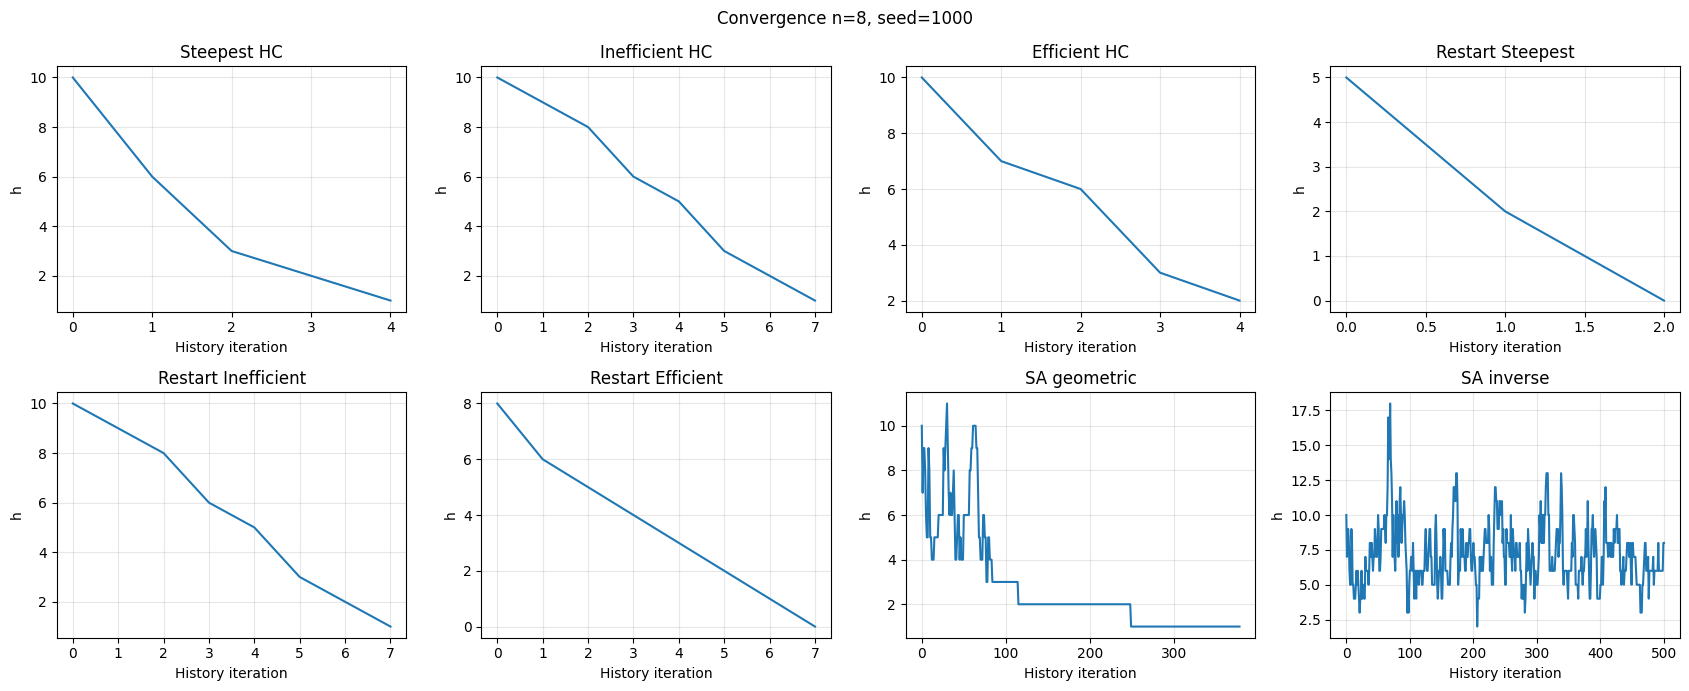

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, label in zip(axes.flat, configs):
    r = next(r for r in benchmark_records if r['n'] == 8 and r['seed'] == 1000 and r['algorithm'] == label)
    ax.plot(range(len(r['history'])), r['history'])
    ax.set_title(label); ax.set_xlabel('History iteration'); ax.set_ylabel('h'); ax.grid(alpha=.3)
fig.suptitle('Convergence n=8, seed=1000'); fig.tight_layout(); plt.show()

### Quy mô và độ phức tạp thực nghiệm

Đo hai HC trên cùng 10 seed mới (2000–2009) cho mỗi n=4,8,12,16,20; dùng trung bình số học thời gian toàn bộ lời gọi. Hệ số góc được hồi quy tuyến tính của log(thời gian trung bình) theo log(n). Đây chỉ là độ phức tạp thực nghiệm trên miền nhỏ, phụ thuộc máy, cài đặt, ngân sách và phân phối đầu vào; không chứng minh Big O hay ngoại suy đáng tin cậy.

Steepest HC: log-log slope = 3.72; mean time (ms) = [ 0.111  1.359  6.294 17.543 45.538]
Efficient HC: log-log slope = 2.55; mean time (ms) = [ 0.493  1.938  6.745 14.54  29.56 ]


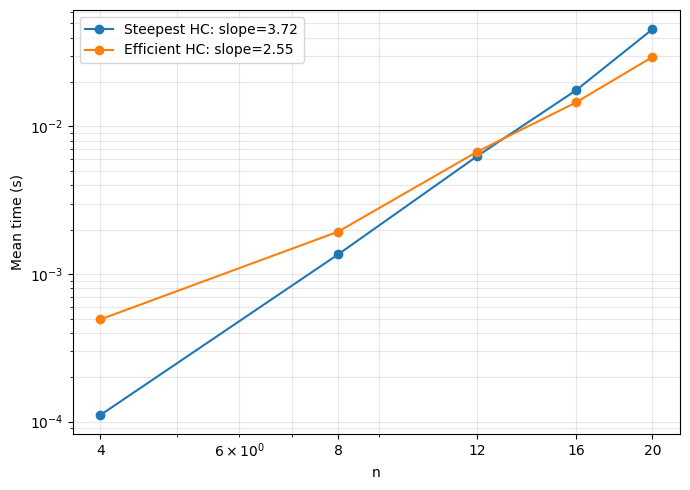

In [12]:
scale_configs = {k: configs[k] for k in ('Steepest HC', 'Efficient HC')}
scale_records = benchmark(scale_configs, (4, 8, 12, 16, 20), range(2000, 2010))
fig, ax = plt.subplots(figsize=(7, 5))
for label in scale_configs:
    ns = np.array([4, 8, 12, 16, 20])
    times = np.array([mean(r['runtime_s'] for r in scale_records if r['n'] == n and r['algorithm'] == label) for n in ns])
    slope, intercept = np.polyfit(np.log(ns), np.log(times), 1)
    ax.loglog(ns, times, 'o-', label=f'{label}: slope={slope:.2f}')
    print(f'{label}: log-log slope = {slope:.2f}; mean time (ms) = {np.round(times*1000, 3)}')
ax.set_xticks(ns, labels=ns); ax.set_xlabel('n'); ax.set_ylabel('Mean time (s)'); ax.grid(True, which='both', alpha=.3); ax.legend(); fig.tight_layout(); plt.show()

### Nhận xét và trả lời thảo luận

1. **Complete và consistent:** complete yêu cầu gán đủ biến; consistent kiểm tra miền và các ràng buộc đã xác định. Nghiệm phải thỏa cả hai.
2. **MRV và Forward Checking:** MRV chọn biến còn ít giá trị hợp lệ; Forward Checking tỉa miền láng giềng sau gán và hoàn tác khi quay lui. Cả hai có chi phí riêng và không luôn nhanh hơn trên mẫu nhỏ.
3. **Tô màu ba màu:** Forward Checking chỉ chứng minh vô nghiệm khi duyệt hết mà không chạm giới hạn; Min-Conflicts hết bước không chứng minh vô nghiệm. Bảng notebook tô màu dùng 3/4 màu, n=10,20,30 và ba seed; kết luận chỉ áp dụng các instance đó.
4. **Local optimum và plateau:** HC chỉ nhận cải thiện nghiêm ngặt nên có thể dừng khi h>0. Restart thử điểm bắt đầu khác; SA có thể nhận bước xấu theo nhiệt độ và thoát một số bẫy, nhưng không bảo đảm thành công trong ngân sách hữu hạn.
5. **Ba HC:** Steepest và Inefficient duyệt toàn bộ n(n−1) láng giềng mỗi vòng; Efficient lấy mẫu đến cải thiện đầu tiên hoặc hết số lần thử. Số đánh giá không đồng nghĩa thời gian do chi phí điều khiển khác nhau.
6. **Nhiều lượt và điều kiện:** 100 bàn cờ theo seed giúp đo biến thiên và tỷ lệ thành công thay vì dựa trên một ví dụ. Dùng cặp bàn cờ và seed chung, công bố ngân sách, tham số, môi trường và giữ từng lượt giúp tái lập; thời gian vẫn thay đổi theo tải máy. 100 lượt không đại diện cho mọi bàn cờ và biểu đồ một lượt không chứng minh xu hướng chung.

Trong lần chạy này, ở n=8 các HC đơn đạt tỷ lệ thành công thấp hơn các cấu hình Restart; kết quả cụ thể và thời gian xem trong bảng. Không thể suy rộng từ một cấu hình rằng một lịch SA luôn kém hơn. Đối chiếu bảng tô màu: số seed chỉ bằng ba; effort là số lần thử giá trị của Forward Checking hoặc số bước Min-Conflicts, không cùng đơn vị. Xung đột trung bình của Forward Checking chỉ tính các lượt có giá trị đo được. Các hệ số log-log là mô tả thực nghiệm, không phải cận lý thuyết.

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

Phần Advanced task và Genetic Algorithm ở trên là nội dung tùy chọn, chưa thực hiện trong phạm vi tám bài bắt buộc.